In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv("/content/Admission_Predict - Admission_Predict.csv")

In [ ]:
df


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65
...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1.0,0.82
396,397,325,107,3,3.0,3.5,9.11,1.0,0.84
397,398,330,116,4,5.0,4.5,9.45,1.0,0.91
398,399,312,103,3,3.5,4.0,8.78,0.0,0.67


In [ ]:
df['Admit'] = (df['Chance of Admit']>0.87).astype(int)
df

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92,1
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76,0
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72,0
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80,0
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65,0
...,...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1.0,0.82,0
396,397,325,107,3,3.0,3.5,9.11,1.0,0.84,0
397,398,330,116,4,5.0,4.5,9.45,1.0,0.91,1
398,399,312,103,3,3.5,4.0,8.78,0.0,0.67,0


In [ ]:
df = df.drop(columns=['Chance of Admit','Serial No.'])
df

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [ ]:
df.isna().sum()


,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,3
Admit,0


In [ ]:
# Missing values will be imputed after the train-test split to avoid data leakage.
df.isna().sum()


,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,3
Admit,0


In [ ]:
df.isna().sum()

,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,3
Admit,0


In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['Admit'])
y = df['Admit']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Impute missing numeric values using training-set medians only.
train_medians = X_train.median(numeric_only=True)
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)


In [ ]:
df

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [ ]:
df.describe()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,397.000000,400.000000
mean,316.807500,107.410000,3.087500,3.400000,3.452500,8.598925,0.546599,0.175000
std,11.473646,6.069514,1.143728,1.006869,0.898478,0.596317,0.498452,0.380443
min,290.000000,92.000000,1.000000,1.000000,1.000000,6.800000,0.000000,0.000000
25%,308.000000,103.000000,2.000000,2.500000,3.000000,8.170000,0.000000,0.000000
50%,317.000000,107.000000,3.000000,3.500000,3.500000,8.610000,1.000000,0.000000
75%,325.000000,112.000000,4.000000,4.000000,4.000000,9.062500,1.000000,0.000000
max,340.000000,120.000000,5.000000,5.000000,5.000000,9.920000,1.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GRE Score          400 non-null    int64  
 1   TOEFL Score        400 non-null    int64  
 2   University Rating  400 non-null    int64  
 3   SOP                400 non-null    float64
 4   LOR                400 non-null    float64
 5   CGPA               400 non-null    float64
 6   Research           397 non-null    float64
 7   Admit              400 non-null    int64  
dtypes: float64(4), int64(4)
memory usage: 25.1 KB


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score,recall_score, f1_score

In [ ]:
ap_entropy = DecisionTreeClassifier(criterion='entropy')
ap_entropy.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy')

In [ ]:
y_pred1 = ap_entropy.predict(X_train)

In [ ]:
confusion_matrix(y_train,y_pred1)

array([[264,   0],
       [  0,  56]])

In [ ]:
accuracy = accuracy_score(y_train,y_pred1)
precision = precision_score(y_train,y_pred1)
recall = recall_score(y_train,y_pred1)
f1 = f1_score(y_train,y_pred1)
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [ ]:
y_pred = ap_entropy.predict(X_test)

In [ ]:
confusion_matrix(y_test,y_pred)

array([[64,  2],
       [ 2, 12]])

In [ ]:
accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 0.95
Precision: 0.8571428571428571
Recall: 0.8571428571428571
F1 Score: 0.8571428571428571


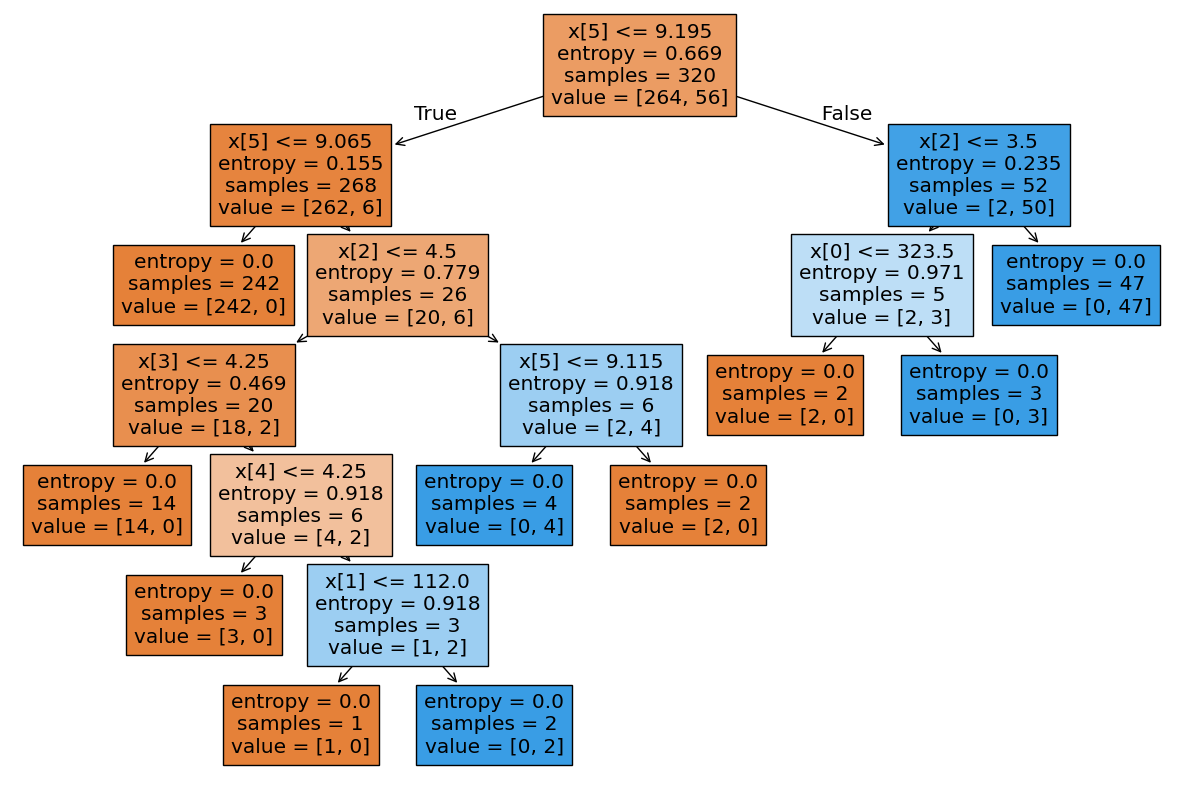

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(15,10))
plot_tree(ap_entropy, filled=True)
plt.show()

In [ ]:
ap_gini = DecisionTreeClassifier(criterion='gini')
ap_gini.fit(X_train, y_train)

DecisionTreeClassifier()

In [ ]:
y_pred1_ginni = ap_gini.predict(X_train)

In [ ]:
confusion_matrix(y_train,y_pred1_ginni)

array([[264,   0],
       [  0,  56]])

In [ ]:
accuracy_gini = accuracy_score(y_train,y_pred1_ginni)
precision_gini = precision_score(y_train,y_pred1_ginni)
recall_gini = recall_score(y_train,y_pred1_ginni)
f1_gini = f1_score(y_train,y_pred1_ginni)
print(f"Accuracy: {accuracy_gini}")
print(f"Precision: {precision_gini}")
print(f"Recall: {recall_gini}")
print(f"F1 Score: {f1_gini}")

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [ ]:
y_pred_ginni = ap_gini.predict(X_test)

In [ ]:
confusion_matrix(y_test,y_pred_ginni)

array([[64,  2],
       [ 3, 11]])

In [ ]:
accuracy_gini = accuracy_score(y_test,y_pred_ginni)
precision_gini = precision_score(y_test,y_pred_ginni)
recall_gini = recall_score(y_test,y_pred_ginni)
f1_gini = f1_score(y_test,y_pred_ginni)
print(f"Accuracy: {accuracy_gini}")
print(f"Precision: {precision_gini}")
print(f"Recall: {recall_gini}")
print(f"F1 Score: {f1_gini}")

Accuracy: 0.9375
Precision: 0.8461538461538461
Recall: 0.7857142857142857
F1 Score: 0.8148148148148148


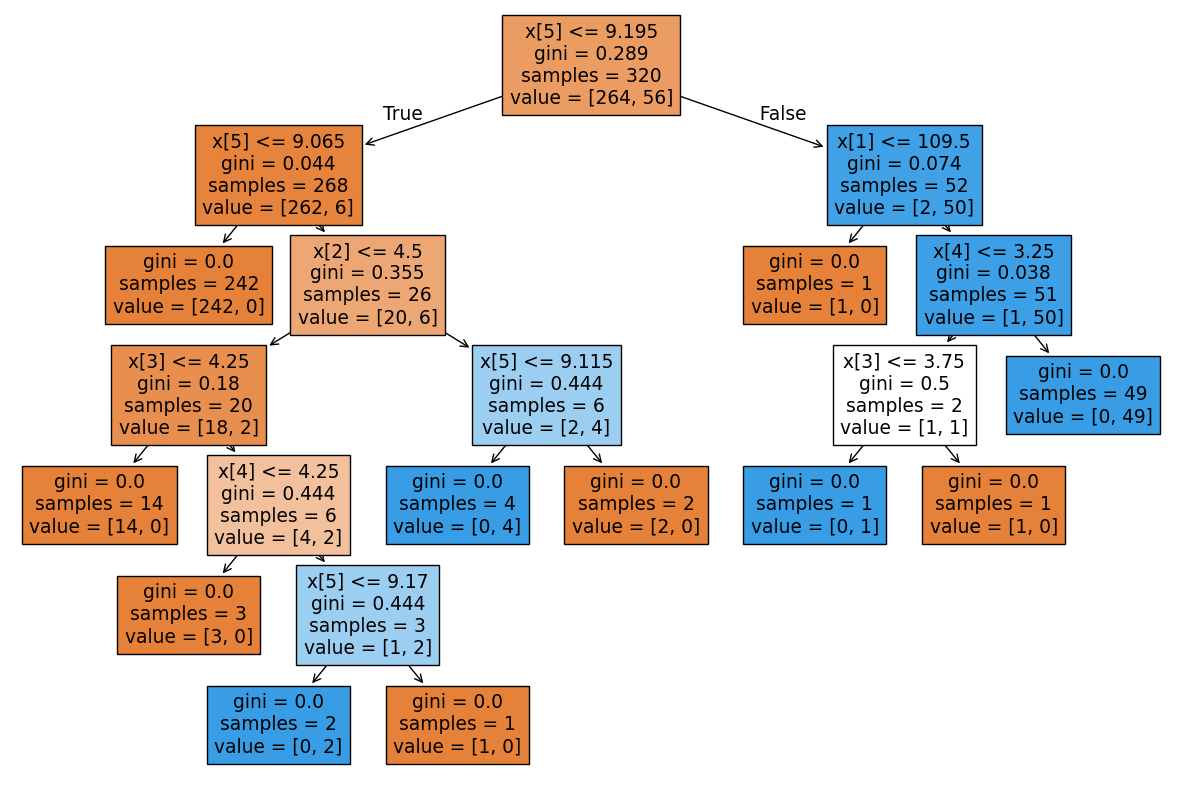

In [ ]:
plt.figure(figsize=(15,10))
plot_tree(ap_gini,filled = True)
plt.show()

In [ ]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train, y_train)

GaussianNB()

In [ ]:
y_pred_nb = nb.predict(X_train)

In [ ]:
confussion_matrix_nb = confusion_matrix(y_train,y_pred_nb)
confussion_matrix_nb

array([[246,  18],
       [  2,  54]])

In [ ]:
accuracy_nb = accuracy_score(y_train,y_pred_nb)
precision_nb = precision_score(y_train,y_pred_nb)
recall_nb = recall_score(y_train,y_pred_nb)
f1_nb = f1_score(y_train,y_pred_nb)
print(f"Accuracy: {accuracy_nb}")
print(f"Precision: {precision_nb}")
print(f"Recall: {recall_nb}")
print(f"F1 Score: {f1_nb}")

Accuracy: 0.9375
Precision: 0.75
Recall: 0.9642857142857143
F1 Score: 0.84375


In [ ]:
y_pred1_nb = nb.predict(X_test)

In [ ]:
confussion_matrix_nb = confusion_matrix(y_test,y_pred1_nb)
confussion_matrix_nb

array([[59,  7],
       [ 0, 14]])

In [ ]:
accuracy_nb = accuracy_score(y_test,y_pred1_nb)
precision_nb = precision_score(y_test,y_pred1_nb)
recall_nb = recall_score(y_test,y_pred1_nb)
f1_nb = f1_score(y_test,y_pred1_nb)
print(f"Accuracy: {accuracy_nb}")
print(f"Precision: {precision_nb}")
print(f"Recall: {recall_nb}")
print(f"F1 Score: {f1_nb}")

Accuracy: 0.9125
Precision: 0.6666666666666666
Recall: 1.0
F1 Score: 0.8


In [ ]:
X_train

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
328,324,112,4,4.0,3.5,8.77,1.0
279,304,102,2,3.0,4.0,8.73,0.0
98,332,119,4,5.0,4.5,9.24,1.0
291,300,102,2,1.5,2.0,7.87,0.0
265,313,102,3,2.5,2.5,8.68,0.0
...,...,...,...,...,...,...,...
183,314,110,3,4.0,4.0,8.80,0.0
186,317,107,3,3.5,3.0,8.68,1.0
149,311,106,2,3.5,3.0,8.26,1.0
102,314,106,2,4.0,3.5,8.25,0.0


In [ ]:
x = X_train[['GRE Score','TOEFL Score']]

In [ ]:
nb1 = GaussianNB()
nb1.fit(x,y_train)
y_pred_new= nb1.predict(x)

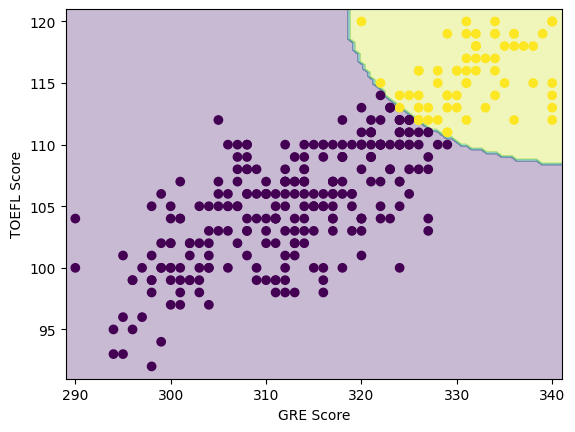

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

DecisionBoundaryDisplay.from_estimator(nb1,x,response_method='predict',alpha=0.3)
plt.scatter(x['GRE Score'] ,x['TOEFL Score'],c =y_pred_new )

In [ ]:
df

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [ ]:
gre = float(input("GRE Score (290-340): "))
toefl = float(input("TOEFL Score (90-120): "))
rating = float(input("University Rating (1-5): "))
sop = float(input("SOP Strength (1-5): "))
lor = float(input("LOR Strength (1-5): "))
cgpa = float(input("CGPA (1-10): "))
research = float(input("Research Experience (1 for Yes, 0 for No): "))

new_data = pd.DataFrame([{
    'GRE Score': gre,
    'TOEFL Score': toefl,
    'University Rating': rating,
    'SOP': sop,
    'LOR': lor,
    'CGPA': cgpa,
    'Research': research
}])


GRE Score (290-340): 320
TOEFL Score (90-120): 100
University Rating (1-5): 5
SOP Strength (1-5): 5
LOR Strength (1-5): 5
CGPA (1-10): 9
Research Experience (1 for Yes, 0 for No): 1


In [ ]:
prediction = ap_entropy.predict(new_data)
if prediction == 0:
  print('You are not eligible for admission')
else:
  print('You are eligible for admission')

You are not eligible for admission


In [ ]:
prediction = ap_gini.predict(new_data)
if prediction == 0:
  print('You are not eligible for admission')
else:
  print('You are eligible for admission')

You are not eligible for admission


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
results = []
for model_name, predictions in [
    ("Decision Tree (Entropy)", y_pred),
    ("Decision Tree (Gini)", y_pred_ginni),
    ("Gaussian Naive Bayes", y_pred1_nb),
]:
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
    })
comparison_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False)
display(comparison_df.round(3))
best_model = comparison_df.iloc[0]["Model"]
print(f"Most suitable model on this test split (highest F1 Score): {best_model}")


,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree (Entropy),0.950,0.857,0.857,0.857
1,Decision Tree (Gini),0.938,0.846,0.786,0.815
2,Gaussian Naive Bayes,0.912,0.667,1.000,0.800


Most suitable model on this test split (highest F1 Score): Decision Tree (Entropy)


In [ ]:
df

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [ ]:
df

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0
